# 02 · One-step DNS by maximum likelihood (Kalman filter), USD

The same dynamic Nelson–Siegel model as notebook 01, but estimated in one step
(README §6.3). All parameters (factor means μ, VAR matrix A, shock covariance Q,
the 17 measurement-error variances, and optionally λ) are chosen to maximise
the Kalman-filter likelihood of the observed yields. The filter is written
from scratch (`src/yck/model/kalman.py`) and checked against statsmodels.

Same sample as notebook 01: estimation from **1985-01**, forecast origins
from **2000-01**. Parameters are re-estimated every 12 months (warm-started),
and forecasts start from **filtered** states, so nothing uses data after the
origin.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from yck.model.dns import fit_factors, fit_rmse_bp, DL_LAMBDA, ns_loadings
from yck.model.statespace_dns import fit_dns_mle
from yck.eval.backtest import dns_two_step_forecasts, dns_kalman_forecasts, random_walk_forecasts, rmse_table

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "data/results"
EST_START, FIRST_ORIGIN, H = "1985-01-31", "2000-01-31", (1, 6, 12)
y = pd.read_parquet(ROOT / "data/processed/curves_USD.parquet").loc[EST_START:]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(y)} months, {y.index[0]:%Y-%m} to {y.index[-1]:%Y-%m}")

502 months, 1985-01 to 2026-10


## 1. Full-sample estimates: fixed vs estimated λ

λ sets where the curvature loading peaks. Diebold–Li fix it at 0.0609 (a peak
at about 30 months). Estimating it adds one parameter, so BIC is the fair
comparison.

In [2]:
fits = {"λ fixed (0.0609)": fit_dns_mle(y), "λ estimated": fit_dns_mle(y, estimate_lambda=True)}
summary = pd.DataFrame({
    name: {"log-likelihood": f.loglik, "parameters": f.n_params, "BIC": f.bic, "λ": f.params.lam,
           "curvature peak (months)": 1.7933 / f.params.lam,
           "max |eig(A)|": np.max(np.abs(np.linalg.eigvals(f.params.A))), "seconds": f.seconds}
    for name, f in fits.items()}).T
summary.round(4)

,log-likelihood,parameters,BIC,λ,curvature peak (months),max |eig(A)|,seconds
λ fixed (0.0609),13372.5705,35.0,-26428.3275,0.0609,29.4466,0.9927,71.8585
λ estimated,15666.8667,36.0,-31007.8682,0.0393,45.5852,0.9929,120.2053


In [3]:
for name, f in fits.items():
    print(name)
    print("  mu =", f.params.mu.round(2))
    print("  A  =", np.array2string(f.params.A.round(3), prefix="       "))
    print("  sd(factor shocks), bp:", (100 * np.sqrt(np.diag(f.params.Q))).round(1))

λ fixed (0.0609)
  mu = [ 6.51 -1.85 -1.29]
  A  = [[ 0.987 -0.001  0.019]
        [-0.022  0.944  0.042]
        [ 0.025  0.031  0.929]]
  sd(factor shocks), bp: [31.9 36.4 74.4]
λ estimated
  mu = [ 6.74 -2.09 -0.88]
  A  = [[ 0.982  0.005  0.023]
        [-0.012  0.968  0.02 ]
        [ 0.038  0.021  0.917]]
  sd(factor shocks), bp: [35.3 39.2 88.3]


## 2. Measurement error by maturity

The one-step model estimates a separate noise variance for each maturity, so
the filter trusts precise maturities more. Several come out at essentially
**zero**. This is a known feature of fitting DNS to GSW data: GSW yields are
themselves values of a smooth Svensson curve, not raw bond prices, so a
three-factor curve can match a few maturities almost exactly. The likelihood
is still valid, but it means those maturities pin the factors down. A floor
on the noise standard deviation (e.g. 1 bp) is a possible robustness check.

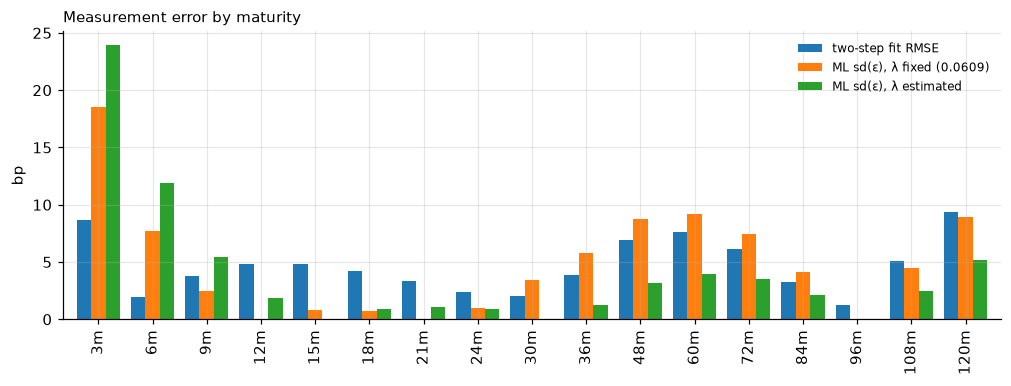

In [4]:
f2 = fit_factors(y)
noise = pd.DataFrame({"two-step fit RMSE": fit_rmse_bp(y, f2)})
for name, f in fits.items():
    noise[f"ML sd(ε), {name}"] = 100 * np.sqrt(f.params.h)
ax = noise.plot.bar(figsize=(11, 3.4), width=0.8)
ax.set_ylabel("bp"); ax.set_title("Measurement error by maturity", loc="left", fontsize=10)
ax.legend(fontsize=8, frameon=False); plt.show()

## 3. Factors: filtered (one-step) vs two-step

Filtered factors use data up to t only. They should look very like the
month-by-month OLS factors, because the yields are precise; the filter mainly
adds smoothing where the cross-section is noisy.

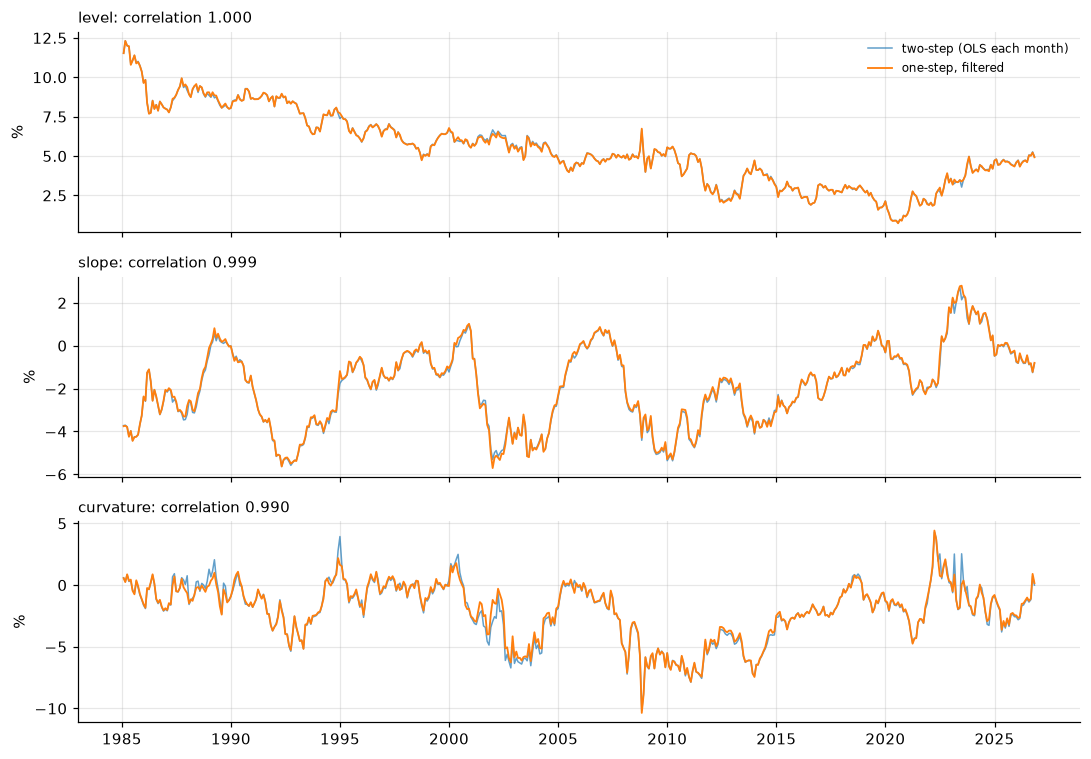

In [5]:
best = fits["λ fixed (0.0609)"]
ff = best.filtered_factors(y)
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, c in zip(axes, ff.columns):
    ax.plot(f2[c], lw=1, alpha=0.7, label="two-step (OLS each month)")
    ax.plot(ff[c], lw=1.2, label="one-step, filtered")
    ax.set_title(f"{c}: correlation {ff[c].corr(f2[c]):.3f}", loc="left", fontsize=10); ax.set_ylabel("%")
axes[0].legend(fontsize=8, frameon=False); fig.tight_layout()

## 4. Out-of-sample forecasts vs the random walk

The backtest refits the model 27 times per variant. Results are cached in
`data/results/` (git-ignored); delete them to recompute (about 30–60 min).
The two-step forecasts from notebook 01 are recomputed here, since they take
under a second.

In [6]:
def kalman_fc(tag, estimate_lambda):
    files = {h: RESULTS / f"fc_USD_kalman_{tag}_h{h}.parquet" for h in H}
    if all(p.exists() for p in files.values()):
        return {h: pd.read_parquet(p) for h, p in files.items()}
    RESULTS.mkdir(parents=True, exist_ok=True)
    fc = dns_kalman_forecasts(y, H, FIRST_ORIGIN, estimate_lambda=estimate_lambda, verbose=True)
    for h, df in fc.items():
        df.to_parquet(files[h])
    return fc

models = {
    "two-step AR(1)": dns_two_step_forecasts(y, H, FIRST_ORIGIN, kind="ar1"),
    "two-step VAR(1)": dns_two_step_forecasts(y, H, FIRST_ORIGIN, kind="var1"),
    "Kalman, λ fixed": kalman_fc("lamfixed", False),
    "Kalman, λ estimated": kalman_fc("lamest", True),
}
rw = random_walk_forecasts(y, H, FIRST_ORIGIN)
SHOW = ["3m", "12m", "24m", "60m", "120m"]
tables = {h: rmse_table({**{n: m[h] for n, m in models.items()}, "RW": rw[h]}, y) for h in H}
ratio = pd.concat({f"h={h}": tables[h][list(models)].div(tables[h]["RW"], axis=0).loc[SHOW] for h in H})
ratio.round(2).join(pd.concat({f"h={h}": tables[h][["RW"]].loc[SHOW] for h in H}).round(1)
                    .rename(columns={"RW": "RW RMSE (bp)"}))

two-step AR(1)  two-step VAR(1)  Kalman, λ fixed  \
h=1  3m              1.08             0.86             1.02   
     12m             1.08             0.98             0.98   
     24m             1.05             1.00             1.01   
     60m             1.14             1.08             1.10   
     120m            1.04             1.05             1.06   
h=6  3m              1.09             0.84             0.87   
     12m             1.14             0.95             0.98   
     24m             1.16             1.01             1.04   
     60m             1.20             1.08             1.13   
     120m            1.08             1.03             1.07   
h=12 3m              1.06             0.88             0.92   
     12m             1.10             0.96             1.00   
     24m             1.15             1.02             1.07   
     60m             1.26             1.12             1.20   
     120m            1.17             1.07             1.17   

           Kalman, λ estimated  RW RMSE (bp)  
h=1  3m                   1.02          23.7  
     12m                  0.98          21.7  
     24m                  1.01          24.6  
     60m                  1.03          26.8  
     120m                 1.05          26.7  
h=6  3m                   0.88          86.5  
     12m                  0.99          80.3  
     24m                  1.05          76.0  
     60m                  1.11          67.0  
     120m                 1.10          60.1  
h=12 3m                   0.93         149.1  
     12m                  1.00         138.9  
     24m                  1.07         123.9  
     60m                  1.18          95.8  
     120m                 1.20          80.2

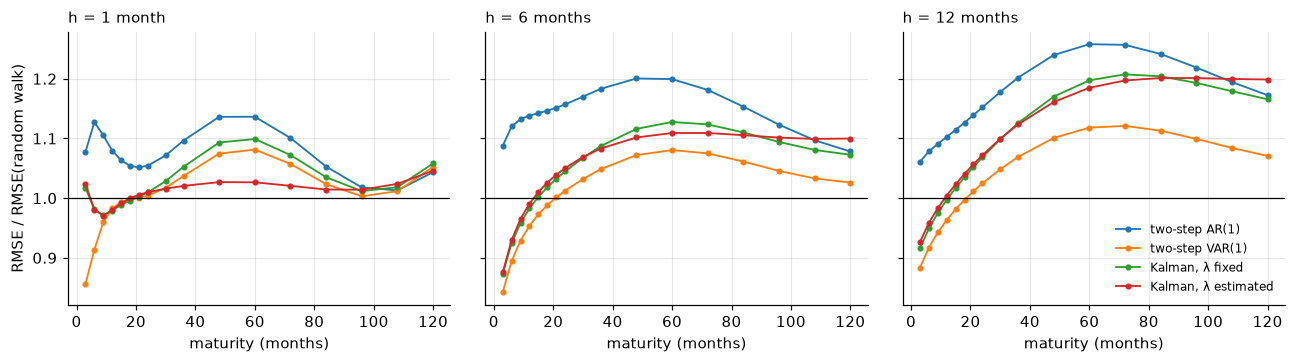

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
mats = [int(c[:-1]) for c in y.columns]
for ax, h in zip(axes, H):
    for n in models:
        ax.plot(mats, tables[h][n] / tables[h]["RW"], marker="o", ms=3, lw=1.2, label=n)
    ax.axhline(1, color="k", lw=0.8)
    ax.set_title(f"h = {h} month" + ("s" if h > 1 else ""), loc="left", fontsize=10)
    ax.set_xlabel("maturity (months)")
axes[0].set_ylabel("RMSE / RMSE(random walk)"); axes[-1].legend(fontsize=8, frameon=False)
fig.tight_layout()

## 5. Is the mean-reversion bias still there?

Notebook 01 found that the two-step forecasts ran too high in 2000–2015,
because they revert to a high historical mean. One-step estimation changes
how the parameters are estimated, but not that mechanism.

In [8]:
h = 12
periods = [("2000", "2007", "2000–07"), ("2008", "2015", "2008–15 (ZLB)"), ("2016", "2026", "2016–")]
err = {n: 100 * (m[h] - y).reindex(rw[h].index) for n, m in {**models, "RW": rw}.items()}
pd.DataFrame({lab: {n: e.loc[a:b, "120m"].mean() for n, e in err.items()} for a, b, lab in periods}).round(0)

,2000–07,2008–15 (ZLB),2016–
two-step AR(1),58.0,80.0,-10.0
two-step VAR(1),47.0,45.0,11.0
"Kalman, λ fixed",66.0,45.0,13.0
"Kalman, λ estimated",68.0,56.0,19.0
RW,20.0,31.0,-22.0


## 6. Parameter stability across re-estimations

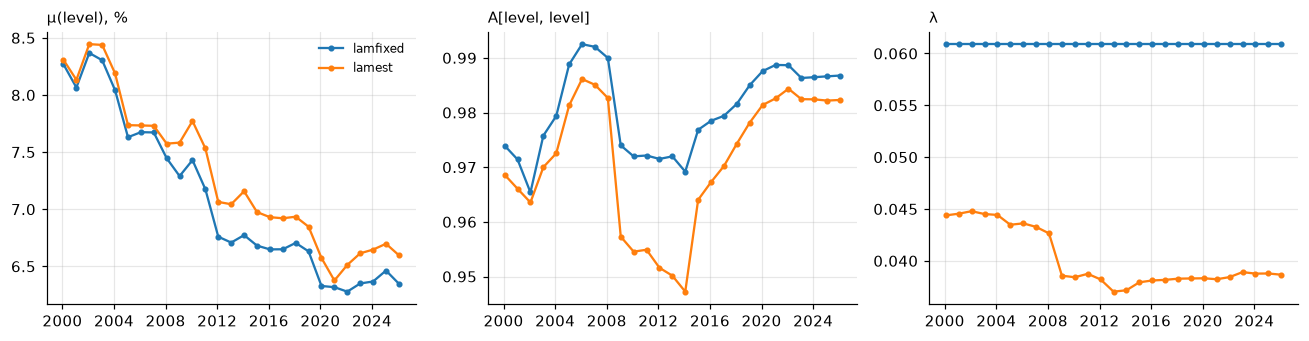

In [9]:
params = {tag: pd.read_csv(RESULTS / f"params_USD_kalman_{tag}.csv", parse_dates=["origin"]).set_index("origin")
          for tag in ("lamfixed", "lamest") if (RESULTS / f"params_USD_kalman_{tag}.csv").exists()}
if params:
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
    for tag, p in params.items():
        for ax, col, title in zip(axes, ["mu0", "A00", "lam"], ["μ(level), %", "A[level, level]", "λ"]):
            ax.plot(p.index, p[col], marker="o", ms=3, label=tag)
            ax.set_title(title, loc="left", fontsize=10)
    axes[0].legend(fontsize=8, frameon=False); fig.tight_layout()

## 7. Takeaways

- **The one-step model fits far better in-sample.** The log-likelihood rises
  from about 11,170 at the two-step estimates to about 13,370 (λ fixed) and
  15,670 (λ estimated, ≈ 0.039, curvature peak at ≈ 46 months). Filtered
  factors are almost the same as the two-step ones.
- **That does not carry over to forecasting.** Out of sample (USD,
  2000–2026), the Kalman model beats the random walk only at the short end
  (3m RMSE ratio ≈ 0.87–0.93 at h = 6, 12). From 2y out it is worse than
  both the random walk and the two-step VAR(1), which remains the best
  yields-only model. Estimating λ improves the likelihood but not the
  forecasts.
- **Mean reversion is still the problem.** At h = 12, 10y forecasts were
  about 66–68 bp too high on average in 2000–07 (two-step VAR: 47, random
  walk: 20). ML estimation makes the factors slightly more mean-reverting
  towards a high historical mean. §6 shows the mechanism: the estimated
  long-run level μ was 6.3–8.4% in every refit, while the 10y yield was
  mostly 1–5%.
- **The optimiser does not reliably find the maximum.** Numerical-gradient
  L-BFGS-B stops early on flat ridges of the likelihood. Cold and warm
  starts disagree by up to ~300 log-likelihood points, and each refit
  keeps the better of the two. This barely matters for forecasts: forecasts
  from the stuck first run and the corrected run differ by 0.2–1.6 bp on
  average, with identical RMSE ratios. The ridge is flat in exactly the
  directions forecasts do not depend on. It still matters for speed (about
  45–60 minutes per backtest) and for the macro model's ~75 parameters, so
  EM plus an analytic score comes next (README §8, step 4b).
- **Implication for the research question.** Better estimation of a
  yields-only model does not fix its forecasting weakness. The question is
  whether *information* does: macro variables (§6.4) and the market's own
  forwards (§7.4), judged both in RMSE and in trading P&L (§7.5).
